### Tests of the RIS

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[0.         3.14159265 0.         3.14159265]
 [3.14159265 0.         3.14159265 0.        ]
 [0.         0.         3.14159265 3.14159265]
 [3.14159265 3.14159265 0.         0.        ]]
[[ 1.+0.0000000e+00j -1.+1.2246468e-16j  1.+0.0000000e+00j
  -1.+1.2246468e-16j]
 [-1.+1.2246468e-16j  1.+0.0000000e+00j -1.+1.2246468e-16j
   1.+0.0000000e+00j]
 [ 1.+0.0000000e+00j  1.+0.0000000e+00j -1.+1.2246468e-16j
  -1.+1.2246468e-16j]
 [-1.+1.2246468e-16j -1.+1.2246468e-16j  1.+0.0000000e+00j
   1.+0.0000000e+00j]]
[[0 1 0 1]
 [1 0 1 0]
 [0 0 1 1]
 [1 1 0 0]]


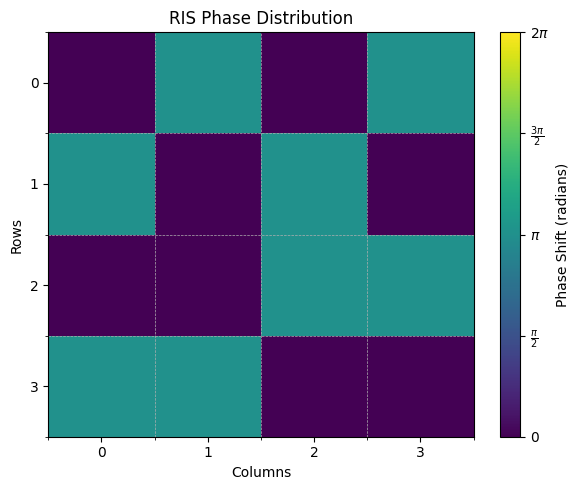

In [2]:
f = 28e9
lam = c/f

ris = RIS(center=[0,0,0],boresight='z',Ncol=4,Nrow=4,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})
print(ris.get_all_phase_shifts())
ris.set_all_state(np.array([[0,1,0,1],[1,0,1,0],[0,0,1,1],[1,1,0,0]]))

print(ris.get_all_phase_shifts())
print(ris.get_all_refl_coef())
print(ris.get_all_state_indices())

ris.plot_phase_dist()


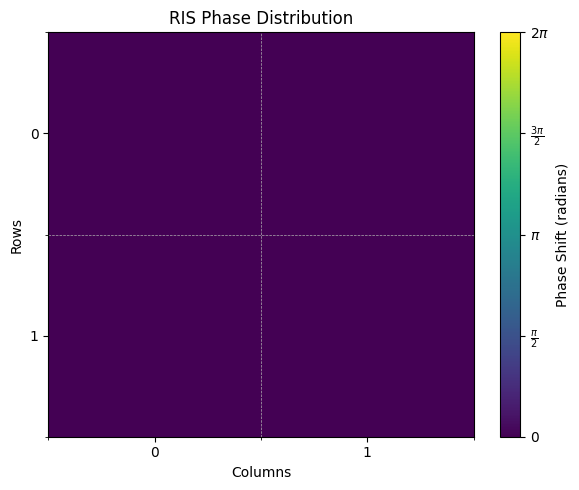

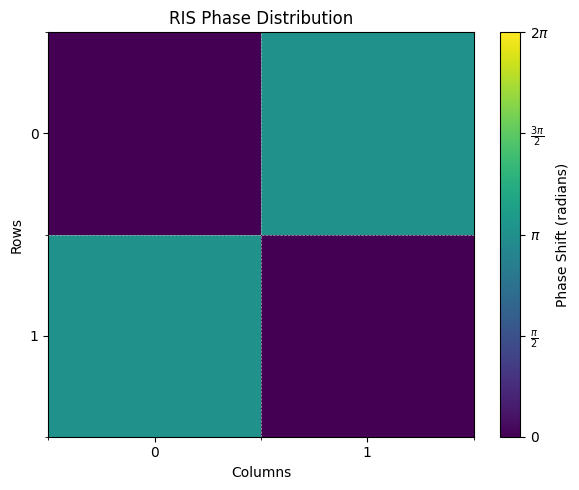

[[0.         3.14159265]
 [3.14159265 0.        ]]
[[ 1.+0.0000000e+00j -1.+1.2246468e-16j]
 [-1.+1.2246468e-16j  1.+0.0000000e+00j]]
[[0 1]
 [1 0]]
False


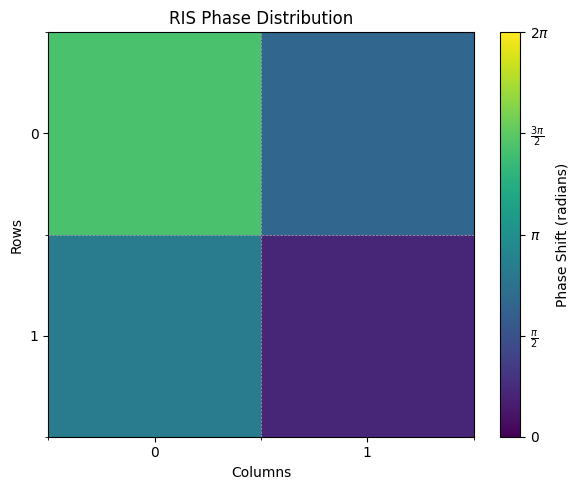

[[4.49140417 2.0416503 ]
 [2.62344009 0.68480414]]
[[-0.21919059-0.97568206j -0.4536475 +0.89118121j]
 [-0.86873565+0.49527605j  0.77454295+0.63252132j]]
[[-1 -1]
 [-1 -1]]
True


In [3]:
ris = RIS(center=[0,0,0],boresight='z',Ncol=2,Nrow=2,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})
ris.plot_phase_dist()

# Normal mode
ris.set_all_shift([[0, np.pi], [pi, 0]], mode='normal')
ris.plot_phase_dist()
print(ris.get_all_phase_shifts())
print(ris.get_all_refl_coef())
print(ris.get_all_state_indices())
print(ris.perfect_phase_enabled)

# Perfect mode
custom_phases = np.random.uniform(0, 2*np.pi, size=(ris.Nrow, ris.Ncol))
ris.set_all_shift(custom_phases, mode='perfect')
ris.plot_phase_dist()
print(ris.get_all_phase_shifts())
print(ris.get_all_refl_coef())
print(ris.get_all_state_indices())
print(ris.perfect_phase_enabled)

In [ ]:
# Test to export the state pattern to csv

# ris.export_pattern_to_csv("testcsv")

Element state matrix exported to testcsv.csv in compact format.
